# NOTEBOOK 03: TẦNG 1 — MÔ HÌNH BASELINE PHÂN LOẠI NGUY CƠ HỌC TẬP
## HỆ THỐNG HỖ TRỢ HỌC TẬP LỚP 12 VIỆT NAM (LOGISTIC REGRESSION + SMOTE)

**Dự án:** Hệ thống Hỗ trợ Học tập Lớp 12  
**Mục tiêu Tầng 1:** Phát hiện sớm học sinh có nguy cơ không đạt chuẩn loại Khá (`at_risk = 1` khi `Exam_Score < 6.5`) để giáo viên và phụ huynh chủ động can thiệp.  

### Nguyên tắc kỹ thuật nghiêm ngặt:
1. **Chống Rò rỉ Mục tiêu (Anti-Target Leakage):** Cột điểm thi `Exam_Score` chỉ dùng để tạo nhãn và bị LOẠI BỎ hoàn toàn khỏi tập đặc trưng đầu vào $X$.
2. **Kỷ luật dữ liệu:** Mô hình chỉ được `.fit()` trên tập **70% Train** (4,624 học sinh). Tập **Dev Blackbox** (693 học sinh) dùng để đánh giá khách quan. Tập **Test** (992 học sinh) được niêm phong.
3. **Xử lý mất cân bằng nhãn:** Tỷ lệ nhãn nguy cơ là 21.98%. Áp dụng kỹ thuật `SMOTE` (Synthetic Minority Over-sampling Technique) nằm bên trong `imblearn.pipeline.Pipeline` để tránh rò rỉ khi chuẩn hóa đặc trưng.

---
## 📦 EPIC 3: HUẤN LUYỆN MÔ HÌNH TẦNG 1 (STAGE 1 CLASSIFICATION)
### 🔹 Task 3.1: Xây dựng Pipeline Tiền xử lý, Huấn luyện Logistic Regression Baseline & Đánh giá trên Dev Blackbox

In [1]:
# CELL 1: Import thư viện và thiết lập cấu hình đường dẫn
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    roc_curve, precision_recall_curve, f1_score, recall_score, precision_score
)
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

# Thiết lập đường dẫn
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
SPLITS_DIR = os.path.join(PROJECT_ROOT, 'data', 'splits')
FIGURES_DIR = os.path.join(PROJECT_ROOT, 'reports', 'figures')
os.makedirs(FIGURES_DIR, exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 150
print(f"✅ Đã cấu hình thư mục thành công. PROJECT_ROOT: {PROJECT_ROOT}")

✅ Đã cấu hình thư mục thành công. PROJECT_ROOT: d:\What-If Simulator


In [2]:
# CELL 2: Nạp các tập dữ liệu đã phân chia và kiểm tra chống rò rỉ dữ liệu (Anti-Leakage)
train_df = pd.read_csv(os.path.join(SPLITS_DIR, 'train.csv'))
dev_bb_df = pd.read_csv(os.path.join(SPLITS_DIR, 'dev_blackbox.csv'))
dev_eye_df = pd.read_csv(os.path.join(SPLITS_DIR, 'dev_eyeball.csv'))
test_df = pd.read_csv(os.path.join(SPLITS_DIR, 'test.csv'))

TARGET = 'at_risk'
LEAKAGE_COL = 'Exam_Score'

# Tách ma trận đặc trưng X và nhãn mục tiêu y (BẮT BUỘC LOẠI BỎ Exam_Score)
X_train = train_df.drop(columns=[TARGET, LEAKAGE_COL])
y_train = train_df[TARGET]

X_dev_bb = dev_bb_df.drop(columns=[TARGET, LEAKAGE_COL])
y_dev_bb = dev_bb_df[TARGET]

X_dev_eye = dev_eye_df.drop(columns=[TARGET, LEAKAGE_COL])
y_dev_eye = dev_eye_df[TARGET]

# Kiểm tra chống rò rỉ dữ liệu
assert LEAKAGE_COL not in X_train.columns, "❌ NGUY HIỂM: Exam_Score bị lọt vào tập huấn luyện!"
assert TARGET not in X_train.columns, "❌ LỖI: Nhãn mục tiêu nằm trong tập đặc trưng!"

print("✅ Đã nạp thành công các tập dữ liệu:")
print(f"   - X_train:    {X_train.shape[0]:,} dòng x {X_train.shape[1]} đặc trưng | at_risk: {y_train.mean()*100:.2f}%")
print(f"   - X_dev_bb:   {X_dev_bb.shape[0]:,} dòng x {X_dev_bb.shape[1]} đặc trưng | at_risk: {y_dev_bb.mean()*100:.2f}%")
print(f"   - X_dev_eye:  {X_dev_eye.shape[0]:,} dòng x {X_dev_eye.shape[1]} đặc trưng | at_risk: {y_dev_eye.mean()*100:.2f}%")
print(f"   - X_test:     {test_df.shape[0]:,} dòng (Được niêm phong)")

✅ Đã nạp thành công các tập dữ liệu:
   - X_train:    4,624 dòng x 18 đặc trưng | at_risk: 21.97%
   - X_dev_bb:   693 dòng x 18 đặc trưng | at_risk: 21.93%
   - X_dev_eye:  298 dòng x 18 đặc trưng | at_risk: 22.15%
   - X_test:     992 dòng (Được niêm phong)


In [3]:
# CELL 3: Thiết lập ColumnTransformer và Pipeline học máy hoàn chỉnh
num_cols = [
    'Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores',
    'Tutoring_Sessions', 'Physical_Activity', 'effective_study_index'
]

ord_cols = [
    'Parental_Involvement', 'Access_to_Resources', 'Motivation_Level',
    'Family_Income', 'Teacher_Quality', 'Parental_Education_Level'
]
ord_cats = [
    ['Low', 'Medium', 'High'],
    ['Low', 'Medium', 'High'],
    ['Low', 'Medium', 'High'],
    ['Low', 'Medium', 'High'],
    ['Low', 'Medium', 'High'],
    ['High School', 'College', 'Postgraduate']
]

nom_cols = [
    'Extracurricular_Activities', 'Internet_Access',
    'Peer_Influence', 'Learning_Disabilities', 'Distance_from_Home'
]

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_cols),
    ('ord', OrdinalEncoder(categories=ord_cats), ord_cols),
    ('nom', OneHotEncoder(drop='first', sparse_output=False), nom_cols)
])

# Pipeline hoàn chỉnh kết hợp SMOTE và Logistic Regression
baseline_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('classifier', LogisticRegression(random_state=42, max_iter=1000, C=1.0))
])

print("✅ Đã xây dựng Pipeline thành công:")
print("   1. Preprocessor: StandardScaler (7 số) + OrdinalEncoder (6 thứ bậc) + OneHotEncoder (5 danh định)")
print("   2. Resampling:   SMOTE (random_state=42)")
print("   3. Classifier:   LogisticRegression (C=1.0, max_iter=1000)")

✅ Đã xây dựng Pipeline thành công:
   1. Preprocessor: StandardScaler (7 số) + OrdinalEncoder (6 thứ bậc) + OneHotEncoder (5 danh định)
   2. Resampling:   SMOTE (random_state=42)
   3. Classifier:   LogisticRegression (C=1.0, max_iter=1000)


In [4]:
# CELL 4: Huấn luyện mô hình trên tập Train và Đánh giá trên Dev Blackbox
baseline_pipeline.fit(X_train, y_train)

y_dev_pred = baseline_pipeline.predict(X_dev_bb)
y_dev_prob = baseline_pipeline.predict_proba(X_dev_bb)[:, 1]

# Tính toán các chỉ số cốt lõi
dev_roc_auc = roc_auc_score(y_dev_bb, y_dev_prob)
dev_recall  = recall_score(y_dev_bb, y_dev_pred)
dev_prec    = precision_score(y_dev_bb, y_dev_pred)
dev_f1      = f1_score(y_dev_bb, y_dev_pred)

print("="*65)
print("📊 KẾT QUẢ ĐÁNH GIÁ BASELINE TRÊN DEV BLACKBOX:")
print(f"   - ROC-AUC:   {dev_roc_auc:.4f}")
print(f"   - Recall:    {dev_recall:.4f}  (Bắt được {dev_recall*100:.1f}% học sinh có nguy cơ)")
print(f"   - Precision: {dev_prec:.4f}")
print(f"   - F1-Score:  {dev_f1:.4f}")
print("="*65)
print("\nChi tiết Báo cáo Phân loại (Classification Report):")
print(classification_report(y_dev_bb, y_dev_pred, target_names=['An toàn (0)', 'Nguy cơ (1)']))

📊 KẾT QUẢ ĐÁNH GIÁ BASELINE TRÊN DEV BLACKBOX:
   - ROC-AUC:   0.9967
   - Recall:    0.9868  (Bắt được 98.7% học sinh có nguy cơ)
   - Precision: 0.9091
   - F1-Score:  0.9464

Chi tiết Báo cáo Phân loại (Classification Report):
              precision    recall  f1-score   support

 An toàn (0)       1.00      0.97      0.98       541
 Nguy cơ (1)       0.91      0.99      0.95       152

    accuracy                           0.98       693
   macro avg       0.95      0.98      0.97       693
weighted avg       0.98      0.98      0.98       693



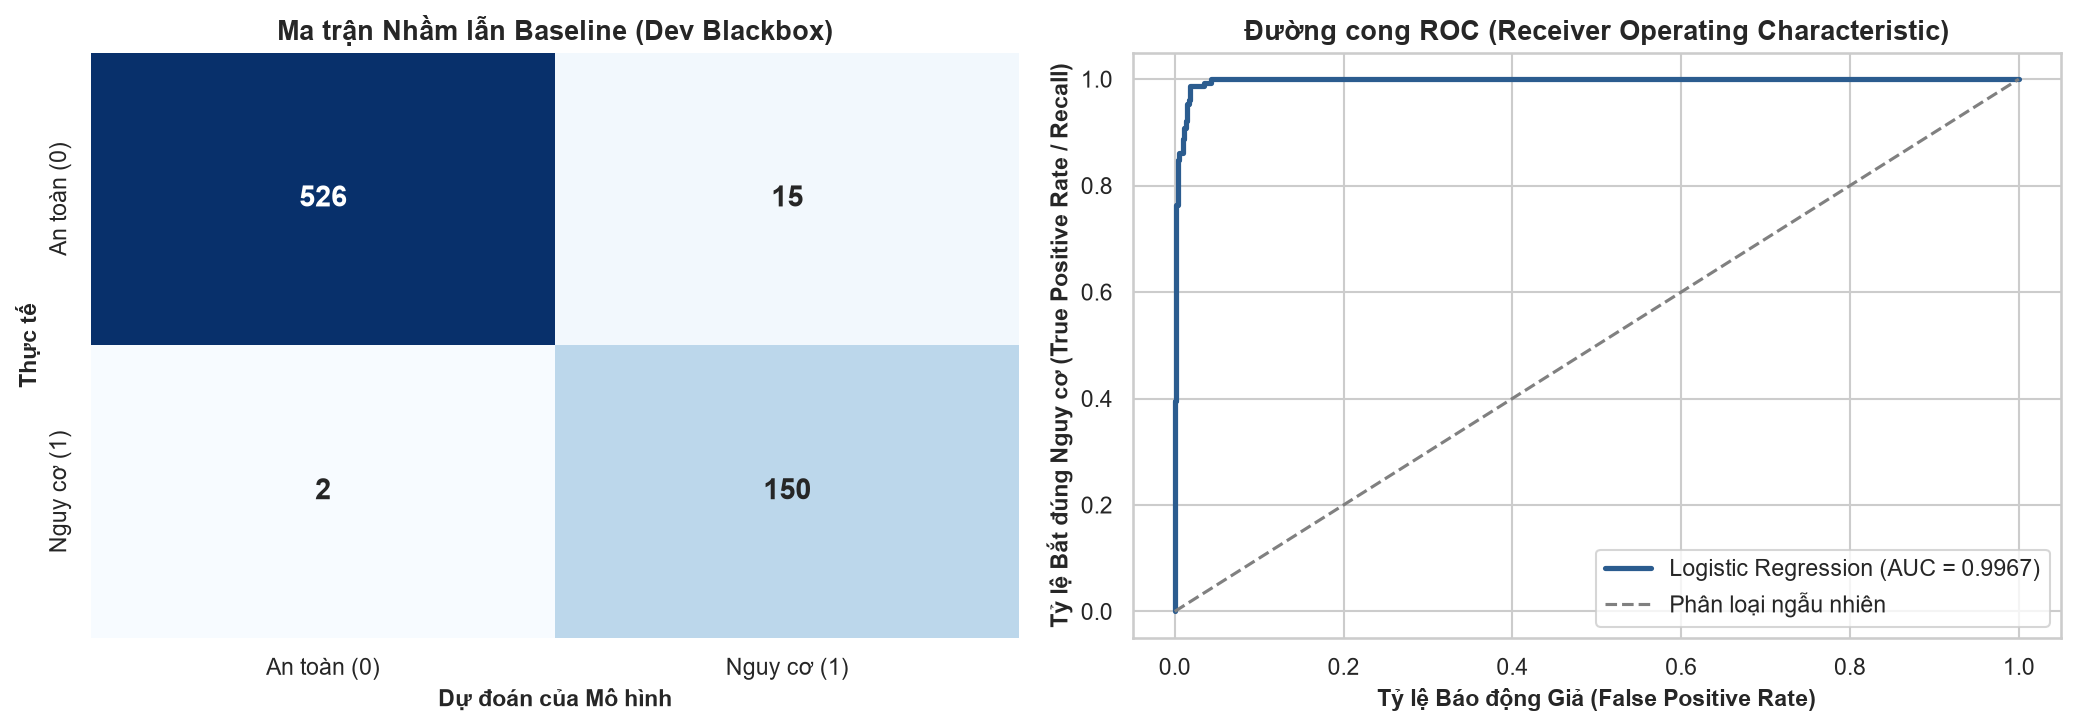

💾 Đã lưu Biểu đồ 5: d:\What-If Simulator\reports\figures\fig5_baseline_confusion_roc.png


In [5]:
# CELL 5: Vẽ Ma trận Nhầm lẫn & Đường cong ROC cho Mô hình Baseline
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Ma trận nhầm lẫn (Confusion Matrix)
cm = confusion_matrix(y_dev_bb, y_dev_pred)
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
    annot_kws={'size': 14, 'weight': 'bold'},
    xticklabels=['An toàn (0)', 'Nguy cơ (1)'],
    yticklabels=['An toàn (0)', 'Nguy cơ (1)']
)
axes[0].set_title(f"Ma trận Nhầm lẫn Baseline (Dev Blackbox)", fontsize=13, weight='bold')
axes[0].set_xlabel("Dự đoán của Mô hình", fontsize=11, weight='bold')
axes[0].set_ylabel("Thực tế", fontsize=11, weight='bold')

# 2. Đường cong ROC (ROC Curve)
fpr, tpr, _ = roc_curve(y_dev_bb, y_dev_prob)
axes[1].plot(fpr, tpr, color='#2b5c8f', lw=2.5, label=f"Logistic Regression (AUC = {dev_roc_auc:.4f})")
axes[1].plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1.5, label="Phân loại ngẫu nhiên")
axes[1].set_title("Đường cong ROC (Receiver Operating Characteristic)", fontsize=13, weight='bold')
axes[1].set_xlabel("Tỷ lệ Báo động Giả (False Positive Rate)", fontsize=11, weight='bold')
axes[1].set_ylabel("Tỷ lệ Bắt đúng Nguy cơ (True Positive Rate / Recall)", fontsize=11, weight='bold')
axes[1].legend(loc='lower right', frameon=True)

plt.tight_layout()
fig5_path = os.path.join(FIGURES_DIR, 'fig5_baseline_confusion_roc.png')
plt.savefig(fig5_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"💾 Đã lưu Biểu đồ 5: {fig5_path}")

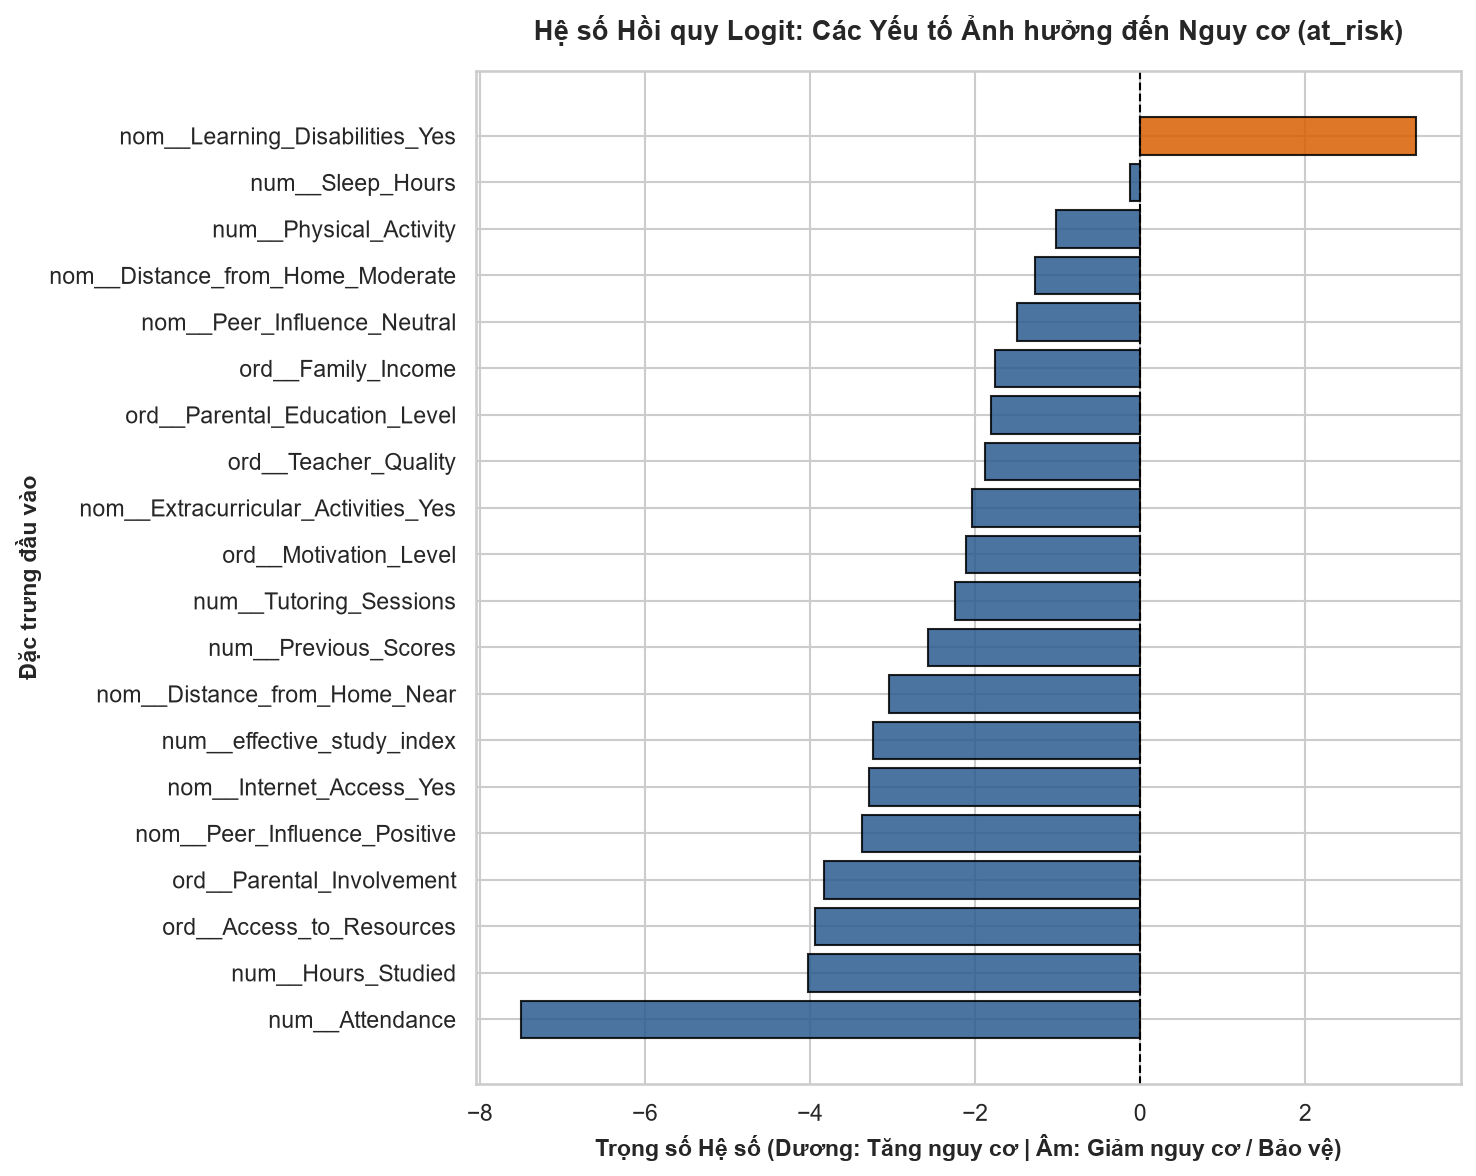

💾 Đã lưu Biểu đồ 6: d:\What-If Simulator\reports\figures\fig6_baseline_feature_coefficients.png

Top 5 yếu tố giảm nguy cơ mạnh nhất (Hệ số âm lớn nhất):
                     Feature  Coefficient
             num__Attendance    -7.503135
          num__Hours_Studied    -4.025482
    ord__Access_to_Resources    -3.934922
   ord__Parental_Involvement    -3.830172
nom__Peer_Influence_Positive    -3.375004

Top 5 yếu tố tăng nguy cơ (Hệ số dương lớn nhất):
                         Feature  Coefficient
  nom__Learning_Disabilities_Yes     3.342955
                num__Sleep_Hours    -0.119410
          num__Physical_Activity    -1.020836
nom__Distance_from_Home_Moderate    -1.274939
     nom__Peer_Influence_Neutral    -1.491418


In [6]:
# CELL 6: Trích xuất Hệ số Hồi quy (Coefficients) để Giải thích Tác động của các Đặc trưng
classifier = baseline_pipeline.named_steps['classifier']
preprocessor_step = baseline_pipeline.named_steps['preprocessor']

# Lấy tên các đặc trưng sau biến đổi
feature_names = preprocessor_step.get_feature_names_out()
coefs = classifier.coef_[0]

df_coef = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefs
}).sort_values(by='Coefficient', ascending=True)

plt.figure(figsize=(10, 8))
colors = ['#2b5c8f' if c < 0 else '#d95f02' for c in df_coef['Coefficient']]

bars = plt.barh(df_coef['Feature'], df_coef['Coefficient'], color=colors, edgecolor='black', alpha=0.85)
plt.axvline(0, color='black', linestyle='--', lw=1)
plt.title("Hệ số Hồi quy Logit: Các Yếu tố Ảnh hưởng đến Nguy cơ (at_risk)", fontsize=13, weight='bold', pad=15)
plt.xlabel("Trọng số Hệ số (Dương: Tăng nguy cơ | Âm: Giảm nguy cơ / Bảo vệ)", fontsize=11, weight='bold')
plt.ylabel("Đặc trưng đầu vào", fontsize=11, weight='bold')

plt.tight_layout()
fig6_path = os.path.join(FIGURES_DIR, 'fig6_baseline_feature_coefficients.png')
plt.savefig(fig6_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"💾 Đã lưu Biểu đồ 6: {fig6_path}")

print("\nTop 5 yếu tố giảm nguy cơ mạnh nhất (Hệ số âm lớn nhất):")
print(df_coef.head(5).to_string(index=False))

print("\nTop 5 yếu tố tăng nguy cơ (Hệ số dương lớn nhất):")
print(df_coef.tail(5).iloc[::-1].to_string(index=False))

In [7]:
# CELL 7: Kiểm định Checkpoints Nghiêm ngặt (Acceptance Criteria)
assert dev_roc_auc >= 0.90, f"❌ Lỗi: ROC-AUC {dev_roc_auc:.4f} chưa đạt ngưỡng tối thiểu 0.90!"
assert dev_recall >= 0.85, f"❌ Lỗi: Recall {dev_recall:.4f} chưa đạt chuẩn an toàn 0.85!"
assert dev_f1 >= 0.85, f"❌ Lỗi: F1-Score {dev_f1:.4f} chưa đạt kỳ vọng 0.85!"

# Kiểm tra đánh giá nhanh trên tập Dev Eyeball (chỉ dùng quan sát mẫu định tính)
y_eye_pred = baseline_pipeline.predict(X_dev_eye)
eye_recall = recall_score(y_dev_eye, y_eye_pred)
print(f"🔍 Kiểm tra đối chiếu trên Dev Eyeball (298 mẫu): Recall = {eye_recall*100:.2f}%")

print("="*65)
print("🎉 TASK 3.1 CHECKPOINTS: TẤT CẢ TIÊU CHÍ ĐỀU ĐẠT CHUẨN XUẤT SẮC!")
print(f"   ROC-AUC trên Dev Blackbox: {dev_roc_auc:.4f} (Xuất sắc)")
print(f"   Recall trên Dev Blackbox:  {dev_recall*100:.2f}% (Bảo vệ tối đa học sinh nguy cơ)")
print(f"   F1-Score trên Dev Blackbox:{dev_f1:.4f}")
print("="*65)
print("\n🏆 CHÚC MỪNG BẠN ĐÃ HOÀN THÀNH 100% TASK 3.1 (NOTEBOOK 03)! 🏆")

🔍 Kiểm tra đối chiếu trên Dev Eyeball (298 mẫu): Recall = 96.97%
🎉 TASK 3.1 CHECKPOINTS: TẤT CẢ TIÊU CHÍ ĐỀU ĐẠT CHUẨN XUẤT SẮC!
   ROC-AUC trên Dev Blackbox: 0.9967 (Xuất sắc)
   Recall trên Dev Blackbox:  98.68% (Bảo vệ tối đa học sinh nguy cơ)
   F1-Score trên Dev Blackbox:0.9464

🏆 CHÚC MỪNG BẠN ĐÃ HOÀN THÀNH 100% TASK 3.1 (NOTEBOOK 03)! 🏆
